Daniel Lillard

2026.11.10

Lets look into the clip_probs.txt file.

In [17]:
import pandas as pd

df = pd.read_csv("clip_probs.txt", sep=": ", header=None, engine='python')
df.columns = ["File", "Probs"]

# breaking out the probs.
df["human_prob"] = df["Probs"].apply(lambda x: eval(x)[0][0])
df["dog_prob"] = df["Probs"].apply(lambda x: eval(x)[1][0])
df["cat_prob"] = df["Probs"].apply(lambda x: eval(x)[2][0])
df["other_prob"] = df["Probs"].apply(lambda x: eval(x)[3][0])

df.drop(columns=["Probs"], inplace=True)

df

,File,human_prob,dog_prob,cat_prob,other_prob
0,00DE549D20.png,0.533037,0.071728,0.023370,0.371864
1,00DE66AB54.png,0.417146,0.025300,0.011068,0.546485
2,00DEE816AE.png,0.361382,0.050576,0.044591,0.543451
3,00DEF2A5BA.png,0.126587,0.057707,0.024837,0.790870
4,00DF2D1D65.png,0.068523,0.026797,0.014463,0.890217
...,...,...,...,...,...
28350,1D27561C2A.png,0.300913,0.049354,0.025299,0.624434
28351,1D2776920B.png,0.500257,0.142103,0.109387,0.248253
28352,1D27A7134F.png,0.741396,0.050832,0.026061,0.181711
28353,1D27BDD783.png,0.269210,0.020748,0.012746,0.697296


In [ ]:
# basic stats
print(df.describe())

         human_prob      dog_prob      cat_prob    other_prob
count  28355.000000  28355.000000  28355.000000  28355.000000
mean       0.350416      0.100222      0.061385      0.487977
std        0.213166      0.133183      0.103726      0.243235
min        0.000446      0.000255      0.000109      0.003436
25%        0.170797      0.034266      0.018557      0.292849
50%        0.331882      0.063872      0.034142      0.481364
75%        0.513129      0.112652      0.063506      0.688037
max        0.981621      0.985768      0.985152      0.998869


In [9]:
max_vals = df[["human_prob", "dog_prob", "cat_prob", "other_prob"]].idxmax(axis=1)

cat_prob        536
dog_prob       1041
human_prob    10397
other_prob    16381
dtype: int64


<Axes: title={'center': 'Max Probability Counts by Class'}>

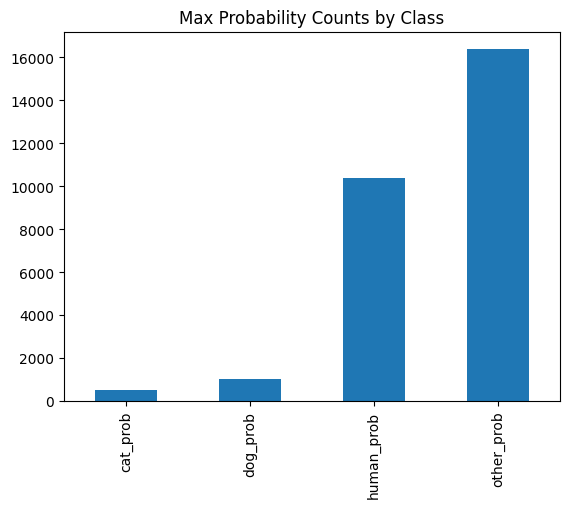

In [15]:
print(max_vals.groupby(by=max_vals).size())
max_vals.groupby(by=max_vals).size().plot(kind='bar', title='Max Probability Counts by Class')

In [18]:
# lets look at some randos where the cat is the highest prob.

df[df["cat_prob"] > 0.5].sample(5)

,File,human_prob,dog_prob,cat_prob,other_prob
12534,0D28A3848F.png,0.006617,0.117402,0.863978,0.012003
403,01372B0F42.png,0.004413,0.007952,0.973934,0.013701
8925,0981874D-B.png,0.007346,0.019009,0.946095,0.027549
17174,11EBA2D0F3.png,0.014475,0.061541,0.747518,0.176465
18562,136169C307.png,0.008249,0.013159,0.870817,0.107774
